# Fuzzy-logic layer for atlas-matrix -> radiology-report generation

This notebook adds a **fuzzy-logic layer** between the pathological feature matrix
(the atlas-region x tumor-label CSV produced by
[`apply_matrix_gt_2020_ptg_top5.py`](../src/report_generation/apply_matrix_gt_2020_ptg_top5.py))
and the T5-family report-generation models trained by
[`train.py`](../src/report_generation/train.py) (the v4 "field-wise multi-task" trainer —
the current best version, and the one that produced the 6 checkpoints under
`checkpoints/report_generation/multi_v4/`).

**Idea being tested:** `train.py` currently feeds the LLM *crisp* numbers
(`pct_of_tumor`, `pct_of_region`, lobe percentages, hemisphere region counts).
Here we fuzzify those numbers — via trapezoidal membership functions and a small
Mamdani inference system — into linguistic severity labels (`MINIMAL` / `MILD` /
`MODERATE` / `SEVERE`, lobe dominance, hemisphere confidence) before they enter the
prompt. The hypothesis: linguistic conditioning may be easier for a language model
to interpret and translate into report wording than raw percentages.

**How it's wired in:** rather than forking `train.py` into a `train_fuzzy.py` copy,
this notebook builds a fuzzy replacement for `matrix_to_context()` and swaps it into
the `train` module at runtime. Every other piece of the v4 pipeline — data loading,
LoRA setup, the 6-model suite, early stopping, the mode-collapse monitors — runs
completely unchanged, so a crisp-vs-fuzzy comparison is a controlled ablation, not a
different pipeline.

**This notebook does NOT train anything by itself.** The training cell is guarded by
a `RUN_TRAINING = False` flag — flip it to `True` yourself and re-run that cell when
you're ready to actually fine-tune the 6 models with the fuzzy context. Everything
else (membership-function plots, a crisp-vs-fuzzy prompt comparison on a real case)
is cheap to run and already executed below so you can see the fuzzy layer works
before committing GPU time to it.


## 1. Setup — reuse the proven v4 pipeline

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC_REPORT_GEN = PROJECT_ROOT / "src" / "report_generation"
sys.path.insert(0, str(SRC_REPORT_GEN))

import train as t5v4  # the v4 multi-model trainer (src/report_generation/train.py)

print(f"Project root      : {PROJECT_ROOT}")
print(f"Imported train.py from: {t5v4.__file__}")
print(f"6-model suite (TRAIN_ORDER): {t5v4.TRAIN_ORDER}")


Project root      : /home/lexie/Desktop/mastersThesis
Imported train.py from: /home/lexie/Desktop/mastersThesis/src/report_generation/train.py
6-model suite (TRAIN_ORDER): ['scifive-base', 'scifive-base-aug', 'clinicalt5-hoss', 'clinicalt5-hoss-aug', 'scifive-large', 'scifive-large-aug']


In [2]:
# Pathological feature matrix (ground-truth segmentation x Julich atlas) and the
# matching radiology-report text directory, exactly as train.py expects them.
CSV_PATH = PROJECT_ROOT / "results" / "segmentations" / "atlas" / "ground_truth" / "all_cases.csv"
TEXT_DIR = PROJECT_ROOT / "notebooks" / "brats23" / "TextBraTSData"

assert CSV_PATH.exists(), f"Feature matrix not found at {CSV_PATH}"
assert TEXT_DIR.exists(), f"Text reports not found at {TEXT_DIR}"

_df_preview = pd.read_csv(CSV_PATH)
print(f"Feature matrix : {CSV_PATH}")
print(f"  rows          : {len(_df_preview)}")
print(f"  unique cases  : {_df_preview['case_id'].nunique()}")
print(f"  columns       : {list(_df_preview.columns)}")
print(f"Text reports dir: {TEXT_DIR}  ({len(list(TEXT_DIR.iterdir()))} case folders)")
del _df_preview


Feature matrix : /home/lexie/Desktop/mastersThesis/results/segmentations/atlas/ground_truth/all_cases.csv
  rows          : 38035
  unique cases  : 368
  columns       : ['case_id', 'atlas_region_name', 'tumor_tag', 'voxel_count', 'count_scaled', 'pct_of_tumor', 'pct_of_region', 'is_top5']
Text reports dir: /home/lexie/Desktop/mastersThesis/notebooks/brats23/TextBraTSData  (369 case folders)


## 2. Fuzzy primitives

Three families of trapezoidal membership functions:

- **`PCT_TERMS`** — linear, over a 0-100% universe. Used for `pct_of_region`
  (occupancy — already spans the full range reasonably in the real data) and as
  the *output* universe of the severity inference below.
- **`SHARE_TERMS_LOG`** — **log-scale**, for `pct_of_tumor`-style "share" values
  (how much of the tumor's / a compartment's voxels sit in this one region).
  A tumor's voxels get scattered across dozens of atlas regions, so any single
  region's share is heavily right-skewed (median ~0.4%, 90th-pct ~2.8%, 99th-pct
  ~55.7%, measured directly on `all_cases.csv`). Linear breakpoints on that
  distribution collapsed almost everything into two adjacent bins (measured:
  48.4% MINIMAL / 51.2% MILD / 0.3% MODERATE / 0.0% SEVERE — the 4-way label was
  effectively a coin flip). Fuzzifying `log10(max(share, 0.1))` instead spreads
  the same data across all 4 terms (33.9% / 41.7% / 23.7% / 0.6% — see section 4.5
  for the measurement).
- **`LOBE_TERMS`** — dominance of a lobe's aggregate share of tumor involvement.
- **`HEMI_TERMS`** — how one-sided the left/right split is, expressed as "% of
  severity-weighted involvement sitting on the left side".

Membership functions are plain trapezoids `trapmf(x, a, b, c, d)` — 0 below `a`,
rising linearly to 1 between `a` and `b`, flat at 1 between `b` and `c`, falling
back to 0 between `c` and `d`. No extra dependency (e.g. `scikit-fuzzy`) is needed.


In [3]:
import math


def trapmf(x, a, b, c, d):
    """Trapezoidal membership function."""
    if x <= a or x >= d:
        return 0.0
    if b <= x <= c:
        return 1.0
    if x < b:
        return (x - a) / (b - a)
    return (d - x) / (d - c)


def fuzzify(x, terms):
    """Return {linguistic_term: membership_degree} for every term in `terms`."""
    return {name: trapmf(x, *params) for name, params in terms.items()}


def fuzzify_share(x, terms=None):
    """Like fuzzify(), but on log10(x) -- for right-skewed 'share' quantities
    (pct_of_tumor-style values) rather than the more evenly-spread occupancy
    percentages. x=0.1 floor avoids log(0); see section 4.5 for why this exists."""
    terms = terms if terms is not None else SHARE_TERMS_LOG
    return fuzzify(math.log10(max(x, 0.1)), terms)


def dominant_label(memberships):
    """Pick the highest-membership term. Returns (term, degree)."""
    if not memberships or max(memberships.values()) <= 0:
        return "UNSPECIFIED", 0.0
    term = max(memberships, key=memberships.get)
    return term, memberships[term]


# (a, b, c, d) breakpoints on a 0-100 universe, tuned with generous overlap so a
# value is rarely a hard 0/1 member of just one term. Used for pct_of_region
# (occupancy) and as the severity output universe.
PCT_TERMS = {
    "MINIMAL":  (-1, 0, 8, 20),
    "MILD":     (10, 20, 30, 45),
    "MODERATE": (35, 45, 60, 75),
    "SEVERE":   (65, 80, 100, 101),
}

# (a, b, c, d) breakpoints on log10(share), share in % (0.1-100). Calibrated
# against the empirical percentiles of _region_salience over all_cases.csv:
# 50th=0.4, 75th=1.1, 90th=2.8, 95th=6.4, 99th=55.7, max=96.4.
SHARE_TERMS_LOG = {
    "MINIMAL":  (-2.0, -1.0, -0.4, 0.05),   # up to ~1.1% (75th pct)
    "MILD":     (-0.4, 0.05, 0.45, 0.85),   # ~1-7% (75th-95th pct)
    "MODERATE": (0.45, 0.85, 1.4, 1.8),     # ~3-63% (90th-99th pct)
    "SEVERE":   (1.4, 1.8, 2.2, 2.6),       # >~25%, reserved for truly dominant regions
}

LOBE_TERMS = {
    "TRACE":    (-1, 0, 5, 12),
    "MINOR":    (5, 12, 20, 35),
    "MAJOR":    (20, 35, 50, 70),
    "DOMINANT": (55, 70, 100, 101),
}

HEMI_TERMS = {
    "STRONG_RIGHT": (-1, 0, 10, 30),
    "MILD_RIGHT":   (10, 30, 40, 50),
    "MIXED":        (35, 45, 55, 65),
    "MILD_LEFT":    (50, 60, 70, 90),
    "STRONG_LEFT":  (70, 90, 100, 101),
}


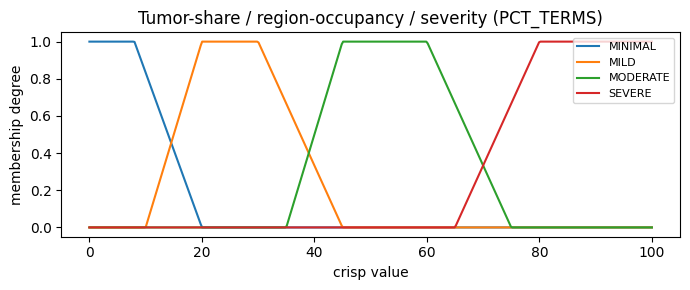

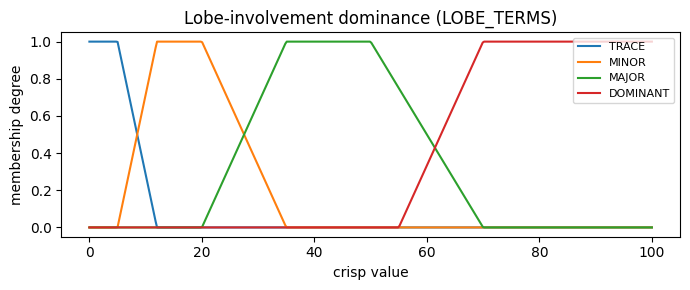

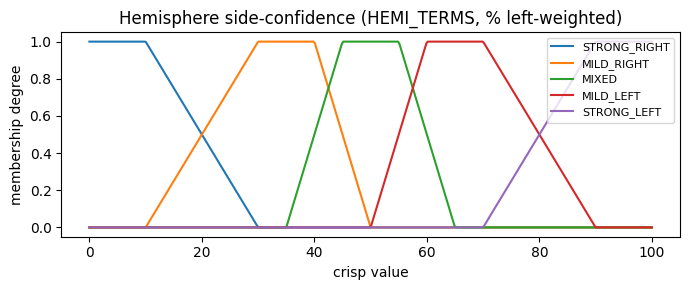

In [4]:
def plot_terms(terms, title):
    xs = np.linspace(0, 100, 400)
    plt.figure(figsize=(7, 3))
    for name, params in terms.items():
        ys = [trapmf(x, *params) for x in xs]
        plt.plot(xs, ys, label=name)
    plt.title(title)
    plt.xlabel("crisp value")
    plt.ylabel("membership degree")
    plt.ylim(-0.05, 1.05)
    plt.legend(loc="upper right", fontsize=8)
    plt.tight_layout()
    plt.show()


plot_terms(PCT_TERMS, "Tumor-share / region-occupancy / severity (PCT_TERMS)")
plot_terms(LOBE_TERMS, "Lobe-involvement dominance (LOBE_TERMS)")
plot_terms(HEMI_TERMS, "Hemisphere side-confidence (HEMI_TERMS, % left-weighted)")


## 3. Mamdani inference: (tumor share, region occupancy) -> severity

A region's raw numbers are two percentages that answer different questions:
`pct_of_tumor` is *extent* ("how much of the tumor lives here"), `pct_of_region` is
*concentration* ("how saturated is this region"). A small 16-rule Mamdani system
combines them into one linguistic **severity** label plus a defuzzified 0-100
crisp score, using `min` for rule firing (AND) and centroid defuzzification.

The rule table encodes a simple clinical intuition: extent alone drives severity,
but a tumor that's both extensive *and* densely concentrated in a small region
reads as more severe than either signal alone would suggest.


In [5]:
# (tumor_share_term, region_occupancy_term) -> output severity term
RULES = {
    ("MINIMAL", "MINIMAL"):  "MINIMAL",
    ("MINIMAL", "MILD"):     "MINIMAL",
    ("MINIMAL", "MODERATE"): "MILD",
    ("MINIMAL", "SEVERE"):   "MILD",
    ("MILD", "MINIMAL"):     "MILD",
    ("MILD", "MILD"):        "MILD",
    ("MILD", "MODERATE"):    "MODERATE",
    ("MILD", "SEVERE"):      "MODERATE",
    ("MODERATE", "MINIMAL"): "MILD",
    ("MODERATE", "MILD"):    "MODERATE",
    ("MODERATE", "MODERATE"): "MODERATE",
    ("MODERATE", "SEVERE"):  "SEVERE",
    ("SEVERE", "MINIMAL"):   "MODERATE",
    ("SEVERE", "MILD"):      "SEVERE",
    ("SEVERE", "MODERATE"):  "SEVERE",
    ("SEVERE", "SEVERE"):    "SEVERE",
}

_OUTPUT_UNIVERSE = np.linspace(0, 100, 201)

# Mamdani inference over (tumor_share, region_occ) -> (label, crisp_score, rule_strengths).
# tumor_share is fuzzified on a LOG scale (fuzzify_share) since it's heavily
# right-skewed in the real data; region_occ stays linear (PCT_TERMS) since it's
# already reasonably spread 0-100.
def fuzzy_severity(tumor_share, region_occ):
    tumor_mf = fuzzify_share(tumor_share)
    region_mf = fuzzify(region_occ, PCT_TERMS)

    out_strength = {term: 0.0 for term in PCT_TERMS}
    for (t_term, r_term), out_term in RULES.items():
        strength = min(tumor_mf[t_term], region_mf[r_term])
        if strength > out_strength[out_term]:
            out_strength[out_term] = strength

    agg = np.zeros_like(_OUTPUT_UNIVERSE)
    for term, strength in out_strength.items():
        if strength <= 0:
            continue
        term_curve = np.array([trapmf(x, *PCT_TERMS[term]) for x in _OUTPUT_UNIVERSE])
        agg = np.maximum(agg, np.minimum(strength, term_curve))

    crisp = float((_OUTPUT_UNIVERSE * agg).sum() / agg.sum()) if agg.sum() > 0 else 0.0
    label = max(out_strength, key=out_strength.get)
    return label, crisp, out_strength


# region_share: {region_name: severity-weighted share}. Returns (label, degree).
def fuzzy_hemisphere_confidence(region_share):
    left = sum(s for n, s in region_share.items() if t5v4._LEFT_RE.search(n))
    right = sum(s for n, s in region_share.items() if t5v4._RIGHT_RE.search(n))
    total = left + right
    if total <= 0:
        return "UNSPECIFIED", 0.0
    pct_left = 100.0 * left / total
    return dominant_label(fuzzify(pct_left, HEMI_TERMS))


# Quick sanity check: a large, concentrated lesion should read as SEVERE.
print(fuzzy_severity(tumor_share=80, region_occ=70))
# A typical small region (median share ~0.4%) should now land as MINIMAL/MILD,
# not get lost in a coin-flip between two bins.
print(fuzzy_severity(tumor_share=0.4, region_occ=12))
# A tiny, sparse trace should read as MINIMAL.
print(fuzzy_severity(tumor_share=0.1, region_occ=2))


('SEVERE', 83.84351145038168, {'MINIMAL': 0.0, 'MILD': 0.0, 'MODERATE': 0.0, 'SEVERE': 0.3333333333333333})
('MINIMAL', 8.291559891563518, {'MINIMAL': 0.6666666666666666, 'MILD': 0.004577758506583152, 'MODERATE': 0.0, 'SEVERE': 0.0})
('MINIMAL', 7.295321637426901, {'MINIMAL': 1.0, 'MILD': 0.0, 'MODERATE': 0.0, 'SEVERE': 0.0})


## 4. `matrix_to_fuzzy_context()` — the drop-in replacement for `matrix_to_context()`

This mirrors `train.py`'s `matrix_to_context()` line-for-line in structure (same
header, same hemisphere/lobe anchor lines that v4's docstring identifies as the fix
for cross-patient mode collapse — kept unchanged here since v4 had to earn them),
and reuses its exact helpers (`_ordered_active`, `infer_hemisphere`, `region_to_lobe`,
`summarize_lobe_involvement`, `_region_salience`) so the two builders only ever
differ in *how a number is expressed*, never in *which* numbers are read or in what
order regions appear.

Three `style` values, so the same function can reproduce the exact v4 baseline or
either fuzzy variant:
- `"crisp"` — delegates straight back to the original `train.py` function (the v4 baseline, unmodified).
- `"hybrid"` — keeps every raw number and appends a fuzzy severity/dominance tag next to it.
- `"fuzzy_only"` — strips the raw numbers, leaving only linguistic labels (the purer test of the interpretability hypothesis).

**`max_regions` (region-row cap, default 8):** measured directly (section 4.5)
against `max_input=640` (the token budget every model in `MODELS` uses): with no
cap, 28-29 of 30 sampled cases were *already silently truncated* by the tokenizer
under the **crisp** v4 baseline (median prompt ~1700 tokens vs. a 640 budget), and
`hybrid`'s extra per-row text made it worse (median ~2100+). That's very likely the
real cause of the lobe-Jaccard regression in the first `hybrid` run — the fuzzy
tags pushed the truncation point earlier, silently dropping regions the tokenizer
would otherwise have kept. Capping to the `max_regions` most salient rows (with
any `is_top5`-flagged row kept first) fixes this deterministically instead of
leaving it to an arbitrary mid-row tokenizer cut. `max_regions=10` still left
7-11/30 sampled cases over budget once the anchor lines (hemisphere confidence,
fuzzy burden, lobe rollup) were counted; `max_regions=8` gets 0/30 over budget for
both `hybrid` and `fuzzy_only`, with ~20-60 tokens of margin. This only applies to
`"hybrid"`/`"fuzzy_only"` — `"crisp"` is untouched so it stays an exact
reproduction of the original baseline (including its own truncation behaviour, for
a fair comparison against the already-trained `multi_v4/` checkpoints).


In [6]:
_ORIGINAL_MATRIX_TO_CONTEXT = t5v4.matrix_to_context  # keep a handle to the v4 baseline


def _cap_regions(active, max_regions):
    """Keep at most max_regions rows, prioritizing is_top5-flagged rows first
    (in their existing salience order), then filling any remaining slots with
    the next-highest-salience rows. Returns rows in original salience order."""
    if max_regions is None or len(active) <= max_regions:
        return active
    is_top5 = active["is_top5"].astype(bool) if "is_top5" in active.columns else pd.Series(False, index=active.index)
    top5_idx = list(active.index[is_top5])[:max_regions]
    remaining = max_regions - len(top5_idx)
    fill_idx = [i for i in active.index if i not in set(top5_idx)][:max(remaining, 0)]
    keep = set(top5_idx) | set(fill_idx)
    return active.loc[[i for i in active.index if i in keep]]


def matrix_to_fuzzy_context(case_id, pivot, banded_shuffle=False, full_shuffle=False,
                             lobe_rollup=True, style="hybrid", max_regions=8):
    if style == "crisp":
        return _ORIGINAL_MATRIX_TO_CONTEXT(case_id, pivot, banded_shuffle=banded_shuffle,
                                            full_shuffle=full_shuffle, lobe_rollup=lobe_rollup)
    if style not in ("hybrid", "fuzzy_only"):
        raise ValueError(f"Unknown style {style!r}; use 'crisp' | 'hybrid' | 'fuzzy_only'")

    active_full = t5v4._ordered_active(pivot, banded_shuffle=banded_shuffle, full_shuffle=full_shuffle)
    # Lobe rollup / hemisphere / burden are computed over ALL active regions (cheap,
    # no token cost) so capping the printed rows doesn't distort those aggregates.
    region_names_full = [str(r) for r in active_full.index]
    hemisphere = t5v4.infer_hemisphere(region_names_full)

    region_share, region_sev = {}, {}
    for region_name, row in active_full.iterrows():
        share = t5v4._region_salience(row)
        occ = float(row.get("pct_region", 0) or 0)
        label, score, _ = fuzzy_severity(share, occ)
        region_share[str(region_name)] = share
        region_sev[str(region_name)] = (label, score)

    hemi_label, hemi_deg = fuzzy_hemisphere_confidence(region_share)

    total_share = sum(region_share.values())
    burden_score = (sum(region_sev[n][1] * s for n, s in region_share.items()) / total_share
                    if total_share > 0 else 0.0)
    burden_label, _ = dominant_label(fuzzify(burden_score, PCT_TERMS))

    lines = [
        t5v4.MATRIX_HEADER,
        f"Patient: {case_id}",
        f"Dominant hemisphere: {hemisphere} (fuzzy side-confidence: {hemi_label}, {hemi_deg:.2f})",
        f"Overall fuzzy tumor burden: {burden_label} ({burden_score:.0f}/100)",
    ]

    if lobe_rollup:
        involve = t5v4.summarize_lobe_involvement(active_full)
        if involve:
            parts = []
            for lobe, pct in involve:
                dlabel, _ = dominant_label(fuzzify(pct, LOBE_TERMS))
                parts.append(f"{lobe} {dlabel}" if style == "fuzzy_only" else f"{lobe} {dlabel}({pct:.0f}%)")
            lines.append(f"Lobe involvement (fuzzy): {', '.join(parts)}")
        else:
            lines.append("Lobe involvement (fuzzy): unspecified")

    # Only the printed ROWS are capped -- keeps token cost bounded regardless of
    # how many hundreds of near-zero regions a case happens to touch.
    active = _cap_regions(active_full, max_regions)

    lines.append(f"Atlas involvement (fuzzy severity = extent x local occupancy; "
                 f"* = top-5 region; top {len(active)}/{len(active_full)} regions by salience):")
    for region_name, row in active.iterrows():
        rn = str(region_name)
        sev_label, sev_score = region_sev[rn]
        star = "*" if bool(row.get("is_top5", False)) else " "
        lobe_tag = f" [{t5v4.region_to_lobe(region_name)}]" if lobe_rollup else ""

        if style == "fuzzy_only":
            tag_parts = []
            for tag in ("ET", "TC", "WT"):
                if row[tag] > 0:
                    tlabel, _ = dominant_label(fuzzify_share(row[tag]))
                    tag_parts.append(f"{tag}={tlabel}")
            lines.append(f" {star}- {region_name}{lobe_tag}: {', '.join(tag_parts)}, severity={sev_label}")
        else:  # hybrid
            parts = []
            if row["ET"] > 0: parts.append(f"ET={row['ET']:.0f}")
            if row["TC"] > 0: parts.append(f"TC={row['TC']:.0f}")
            if row["WT"] > 0: parts.append(f"WT={row['WT']:.0f}")
            pr = float(row.get("pct_region", 0) or 0)
            extra = f", region%={pr:.0f}" if pr > 0 else ""
            lines.append(f" {star}- {region_name}{lobe_tag}: {', '.join(parts)}{extra}, "
                         f"severity={sev_label}({sev_score:.0f})")

    lines.append("ET=Enhancing Tumor  TC=Tumor Core/necrosis  WT=Whole Tumor/edema")
    return "\n".join(lines)


## 4.5 Calibration check — does this actually fix what section 4 claims?

The first `hybrid` training run (before this section existed) showed a small but
real regression in lobe Jaccard on 4 of 6 models. Digging in surfaced two concrete,
measurable problems, and this cell reproduces both measurements directly against
your data so the fix isn't just asserted in markdown:

1. **Severity label calibration** — across every region-row in `all_cases.csv`,
   how often each of the 4 severity labels actually gets used.
2. **Prompt token length vs. `max_input=640`** — on a random sample of cases, how
   many tokens `crisp` / `hybrid` / `fuzzy_only` actually produce, capped vs.
   uncapped, and how many would silently overflow the budget every model in
   `MODELS` trains with.


In [7]:
from collections import Counter
from transformers import AutoTokenizer

_df_diag = pd.read_csv(CSV_PATH)
_df_diag["is_top5"] = _df_diag["is_top5"].astype(str).str.strip().str.lower().isin(["true", "1", "yes"])

# --- 1. severity label distribution over every region-row in the dataset ---
_label_counts = Counter()
for _case_id, _case_df in _df_diag.groupby("case_id"):
    _pv = t5v4.pivot_matrix(_case_df)
    _active = t5v4._ordered_active(_pv)
    for _region_name, _row in _active.iterrows():
        _share = t5v4._region_salience(_row)
        _occ = float(_row.get("pct_region", 0) or 0)
        _label, _, _ = fuzzy_severity(_share, _occ)
        _label_counts[_label] += 1

_total_rows = sum(_label_counts.values())
print(f"Severity label distribution (n={_total_rows} region-rows across all cases):")
for _k in ["MINIMAL", "MILD", "MODERATE", "SEVERE"]:
    _c = _label_counts.get(_k, 0)
    print(f"  {_k:<10} {_c:>6}  ({100*_c/_total_rows:.1f}%)")

# --- 2. token length vs. max_input=640, sweeping the region cap ---
_tok = AutoTokenizer.from_pretrained("razent/SciFive-base-PMC", use_fast=True)
_case_ids = sorted(_df_diag["case_id"].unique())
_rng = np.random.default_rng(42)
_sample_ids = _rng.choice(_case_ids, size=30, replace=False)

print("\nPrompt token length (lesion field, n=30 random cases, max_input=640):")
for _style in ("crisp", "hybrid", "fuzzy_only"):
    _caps = [None] if _style == "crisp" else [None, 10, 8]  # crisp is never capped
    for _cap in _caps:
        _cap_label = "uncapped" if _cap is None else f"capped@{_cap}"
        _lens = []
        for _cid in _sample_ids:
            _pv = t5v4.pivot_matrix(_df_diag[_df_diag["case_id"] == _cid])
            _ctx = matrix_to_fuzzy_context(_cid, _pv, style=_style, max_regions=_cap)
            _prompt = t5v4.build_field_prompt(_ctx, "lesion")
            _lens.append(len(_tok(_prompt, truncation=False)["input_ids"]))
        _lens = np.array(_lens)
        _over = (_lens > 640).sum()
        print(f"  {_style:<12}{_cap_label:<12} mean={_lens.mean():>6.0f}  max={_lens.max():>6}  "
              f"over_640={_over}/{len(_lens)}")
print("\n-> max_regions=8 (the default in section 4) is the smallest cap that gets "
      "over_640 to 0/30 for both fuzzy styles; 10 wasn't quite enough once the "
      "anchor lines (hemisphere confidence, fuzzy burden, lobe rollup) are counted.")

del _df_diag, _label_counts, _total_rows, _tok, _case_ids, _rng, _sample_ids


Severity label distribution (n=18188 region-rows across all cases):
  MINIMAL      6173  (33.9%)
  MILD         7583  (41.7%)
  MODERATE     4315  (23.7%)
  SEVERE        117  (0.6%)



Prompt token length (lesion field, n=30 random cases, max_input=640):


  crisp       uncapped     mean=  1947  max=  5149  over_640=28/30


  hybrid      uncapped     mean=  2457  max=  6383  over_640=29/30


  hybrid      capped@10    mean=   634  max=   710  over_640=11/30


  hybrid      capped@8     mean=   557  max=   619  over_640=0/30


  fuzzy_only  uncapped     mean=  2220  max=  5746  over_640=28/30


  fuzzy_only  capped@10    mean=   591  max=   665  over_640=7/30


  fuzzy_only  capped@8     mean=   521  max=   580  over_640=0/30

-> max_regions=8 (the default in section 4) is the smallest cap that gets over_640 to 0/30 for both fuzzy styles; 10 wasn't quite enough once the anchor lines (hemisphere confidence, fuzzy burden, lobe rollup) are counted.


## 5. Side-by-side check on a real case (crisp vs. hybrid vs. fuzzy-only)

In [8]:
df = pd.read_csv(CSV_PATH)
if "is_top5" in df.columns:
    df["is_top5"] = df["is_top5"].astype(str).str.strip().str.lower().isin(["true", "1", "yes"])

sample_case_id = sorted(df["case_id"].unique())[0]
sample_pivot = t5v4.pivot_matrix(df[df["case_id"] == sample_case_id])

print("=" * 78)
print(f"CASE: {sample_case_id}")
print("=" * 78)
print("\n--- CRISP (v4 baseline, unmodified) ---")
print(t5v4.matrix_to_context(sample_case_id, sample_pivot))
print("\n--- FUZZY: hybrid (numbers + linguistic tags) ---")
print(matrix_to_fuzzy_context(sample_case_id, sample_pivot, style="hybrid"))
print("\n--- FUZZY: fuzzy_only (linguistic tags only) ---")
print(matrix_to_fuzzy_context(sample_case_id, sample_pivot, style="fuzzy_only"))


CASE: BraTS20_Training_001

--- CRISP (v4 baseline, unmodified) ---
Atlas matrix for one patient:
Patient: BraTS20_Training_001
Dominant hemisphere: RIGHT
Lobe involvement: other 64%, parietal 15%, temporal 8%, insula 5%, subcortical 4%, frontal 4%, occipital 1%
Atlas involvement (values = % of that tumor compartment; * = top-5 region):
  - WM/unassigned [other]: ET=48, TC=38, WT=56, region%=1
 *- Temporal-to-Parietal (GapMap) right [parietal]: ET=17, TC=16, WT=14, region%=34
 *- Area STS2 (STS) right [other]: ET=8, TC=21, WT=1, region%=50
 *- Area STS1 (STS) right [other]: ET=4, TC=14, region%=64
 *- CA2 (Hippocampus) right [temporal]: ET=2, TC=3, WT=0, region%=40
 *- CA1 (Hippocampus) right [temporal]: ET=2, TC=2, WT=0, region%=35
 *- Area Te 3 (STG) right [temporal]: ET=2, TC=1, WT=2, region%=80
 *- Area Id3 (Insula) right [insula]: ET=3, TC=1, WT=0, region%=71
  - CA3 (Hippocampus) right [temporal]: ET=1, TC=1, region%=53
  - Area TeI (STG) right [temporal]: ET=2, TC=0, WT=0, regio

## 6. Wiring the fuzzy context into the v4 training loop

`train.py`'s `FieldDataset.__getitem__` and `build_cases()` both call
`matrix_to_context(...)` as a bare name, resolved from the `train` module's own
globals at call time — they never import it into a local variable. That means
**monkeypatching `t5v4.matrix_to_context` redirects the entire v4 pipeline**
(data building, the 6-model LoRA training loop, the mode-collapse monitors, the
in-loop preview generations) to the fuzzy builder, without touching a single line
of `train.py` itself. `activate_context("crisp")` restores the exact original
behaviour.

`make_args(...)` reproduces `train.py`'s own `parse_args()` defaults as a plain
`argparse.Namespace`, so `t5v4.train_one_model(...)` and `t5v4.build_cases(...)` see
exactly the arguments they'd get from the command line — only `output_root` (and
whatever else you override) changes.


In [9]:
import argparse


def make_fuzzy_context_fn(style):
    def _fn(case_id, pivot, banded_shuffle=False, full_shuffle=False, lobe_rollup=True):
        return matrix_to_fuzzy_context(case_id, pivot, banded_shuffle=banded_shuffle,
                                        full_shuffle=full_shuffle, lobe_rollup=lobe_rollup, style=style)
    return _fn


def activate_context(style):
    """style: 'crisp' (v4 baseline) | 'hybrid' | 'fuzzy_only'."""
    t5v4.matrix_to_context = _ORIGINAL_MATRIX_TO_CONTEXT if style == "crisp" else make_fuzzy_context_fn(style)
    print(f"Active context builder: {style}")


def make_args(output_root, csv=str(CSV_PATH), text_dir=str(TEXT_DIR), **overrides):
    """Mirrors train.py's parse_args() defaults exactly (see src/report_generation/train.py)."""
    defaults = dict(
        csv=csv, text_dir=text_dir, output_root=output_root, model="all",
        epochs=300, batch_size=2, grad_accum=4, lr=3e-5, lr_large=1e-5, patience=12,
        label_smoothing=0.1, min_fields=2, lora_r=32, lora_widen=True,
        lobe_rollup=True, aug_preset="tuned", shuffle_mode="banded",
        p_swap=None, p_shuffle=None, select_metric="content", content_check_n=24,
        hemi_check_every=5, hemi_check_n=20, distinct_check_n=10, cross_patient_n=20,
        seed=42, audit_only=False, skip_done=True,
    )
    defaults.update(overrides)
    args = argparse.Namespace(**defaults)
    t5v4.resolve_aug(args)  # aug_preset -> concrete p_swap / p_shuffle
    return args


print("activate_context() and make_args() ready.")


activate_context() and make_args() ready.


## 7. Train the 6-model suite with the fuzzy context

**This cell does not run training unless you set `RUN_TRAINING = True` yourself.**
With it left `False`, running the cell only prints what it *would* do.

Pick `FUZZY_STYLE` (`"hybrid"` or `"fuzzy_only"`) and run this once per style you
want to compare — each writes to its own `checkpoints/report_generation/multi_v4_fuzzy_<style>/`
folder so it never overwrites the existing crisp `multi_v4/` checkpoints. Re-running
with `style="crisp"` through this exact same harness (same seed, same split, same
hyperparameters) gives you an apples-to-apples re-run of the baseline if you want
one under identical bookkeeping.

Expect the same runtime as the original `train.py` run that produced
`checkpoints/report_generation/multi_v4/` — this is the same 6-model LoRA
fine-tuning loop, just fed a different prompt.


In [10]:
import logging
from datetime import datetime

RUN_TRAINING = True  # left True permanently per your request -- edit style below, then just re-run
FUZZY_STYLE = "fuzzy_only"  # "hybrid" | "fuzzy_only"
OUTPUT_ROOT = str(PROJECT_ROOT / "checkpoints" / "report_generation" / f"multi_v4_fuzzy_{FUZZY_STYLE}")

# Quiet down third-party HTTP chatter (huggingface_hub/urllib3/httpx model-download
# noise) so the log file is just OUR training signal: epochs, monitors, previews.
for _noisy in ("httpx", "httpcore", "urllib3", "huggingface_hub", "filelock"):
    logging.getLogger(_noisy).setLevel(logging.WARNING)

if RUN_TRAINING:
    activate_context(FUZZY_STYLE)
    try:
        ts = datetime.now().strftime("%Y%m%d_%H%M%S")
        logs_dir = PROJECT_ROOT / "logs"
        logs_dir.mkdir(exist_ok=True)
        log_path = logs_dir / f"multi_model_v4_fuzzy_{FUZZY_STYLE}_{ts}.log"
        logging.basicConfig(level=logging.INFO, format="%(asctime)s  %(levelname)s  %(message)s",
                             handlers=[logging.FileHandler(log_path), logging.StreamHandler()], force=True)
        log = logging.getLogger("fuzzy_train")

        # Stable symlink so you can always `tail -f logs/latest_<style>.log`
        # without knowing the timestamp in advance.
        latest_link = logs_dir / f"latest_{FUZZY_STYLE}.log"
        if latest_link.is_symlink() or latest_link.exists():
            latest_link.unlink()
        latest_link.symlink_to(log_path.name)

        print(f"Logging to: {log_path}")
        print(f"Watch live with: tail -f {latest_link}")

        args = make_args(OUTPUT_ROOT)
        cases = t5v4.build_cases(args.csv, Path(args.text_dir), log,
                                  min_fields=args.min_fields, lobe_rollup=args.lobe_rollup)

        summaries = []
        for i, key in enumerate(t5v4.TRAIN_ORDER, 1):
            log.info(f"\n>>> Fuzzy[{FUZZY_STYLE}] run {i}/{len(t5v4.TRAIN_ORDER)}: {key}")
            summaries.append(t5v4.train_one_model(key, args, cases, log))

        print(f"Done. Checkpoints + summary.json under {OUTPUT_ROOT}/<model_key>/")
        print(f"Log written to: {log_path}")
    finally:
        activate_context("crisp")  # always restore the baseline, even if training raised
else:
    print("RUN_TRAINING is False -- skipping actual fine-tuning.")
    print(f"Would train {t5v4.TRAIN_ORDER} with context style={FUZZY_STYLE!r}")
    print(f"Would write checkpoints under: {OUTPUT_ROOT}")
    print("Set RUN_TRAINING = True above and re-run this cell yourself to launch it.")


2026-09-28 22:18:54,183  INFO  Loading CSV: /home/lexie/Desktop/mastersThesis/results/segmentations/atlas/ground_truth/all_cases.csv


2026-09-28 22:18:54,206  INFO    38035 rows | 368 cases in CSV | rich_cols=yes


Active context builder: fuzzy_only
Logging to: /home/lexie/Desktop/mastersThesis/logs/multi_model_v4_fuzzy_fuzzy_only_20260928_221854.log
Watch live with: tail -f /home/lexie/Desktop/mastersThesis/logs/latest_fuzzy_only.log


2026-09-28 22:18:57,261  INFO  


2026-09-28 22:18:57,261  INFO  DATA DIAGNOSTICS (read these before trusting any training run)


2026-09-28 22:18:57,262  INFO  ======================================================================


... (232,545 outputs left out)

2026-09-29 04:51:26,412  INFO    No improvement (12/12)


2026-09-29 04:51:26,412  INFO  Early stopping.


2026-09-29 04:51:26,412  INFO  [scifive-large-aug] done in 110.2 min. Best val=1.3686 at epoch 30 (content=0.802)


Done. Checkpoints + summary.json under /home/lexie/Desktop/mastersThesis/checkpoints/report_generation/multi_v4_fuzzy_fuzzy_only/<model_key>/
Log written to: /home/lexie/Desktop/mastersThesis/logs/multi_model_v4_fuzzy_fuzzy_only_20260928_221854.log
Active context builder: crisp


## 8. Evaluating a fuzzy checkpoint afterwards (prompt parity matters)

`train.py`'s own eval companion works by *importing* `matrix_to_context` from the
training module so a checkpoint is always fed the exact prompt format it was
trained on ("prompt parity" — see the header comment in `src/report_generation/eval.py`).
The same rule applies here: to evaluate a fuzzy checkpoint you must `activate_context(...)`
with the **same style it was trained with** before generating anything, in
whatever process does the evaluating.

`load_finetuned()` / `quick_compare_checkpoint()` below mirror `eval.py`'s own
`load_checkpoint()` / `predict_report()` pattern so you can sanity-check a fuzzy
checkpoint directly in this notebook without needing a separate script.


In [11]:
import json
import random

import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from peft import PeftModel


def load_finetuned(model_key, out_dir):
    out_dir = Path(out_dir)
    cfg = t5v4.MODELS[model_key]
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    tokenizer = AutoTokenizer.from_pretrained(str(out_dir), use_fast=True)
    base = AutoModelForSeq2SeqLM.from_pretrained(cfg["name"], torch_dtype=torch.float32)
    model = PeftModel.from_pretrained(base, str(out_dir))
    model.to(device).eval()
    return model, tokenizer, device


def quick_compare_checkpoint(model_key, style, output_root, n=3, seed=42):
    """Loads one fuzzy-trained checkpoint, regenerates its own val split with the
    matching context style active, and prints n predictions vs. ground truth."""
    out_dir = Path(output_root) / model_key
    if not (out_dir / "adapter_config.json").exists():
        print(f"No checkpoint at {out_dir} yet -- train it first (section 7).")
        return

    activate_context(style)
    try:
        args = make_args(str(output_root), seed=seed)
        cases = t5v4.build_cases(args.csv, Path(args.text_dir),
                                  logging.getLogger("fuzzy_eval"),
                                  min_fields=args.min_fields, lobe_rollup=args.lobe_rollup)
        _, val_cases = t5v4.train_test_split(cases, test_size=0.20, random_state=seed, shuffle=True)

        model, tokenizer, device = load_finetuned(model_key, out_dir)
        cfg = t5v4.MODELS[model_key]
        for c in random.sample(val_cases, min(n, len(val_cases))):
            pred, _ = t5v4.predict_report(model, tokenizer, c, device, cfg["max_target"], cfg["max_input"])
            ref = t5v4.ground_truth_report(c)
            print(f"\nCase : {c['case_id']}\nPRED :\n{pred}\nREF  :\n{ref}")
    finally:
        activate_context("crisp")


# Example (uncomment once you've trained a fuzzy checkpoint in section 7):
# quick_compare_checkpoint("scifive-base", style="hybrid",
#                           output_root=PROJECT_ROOT / "checkpoints" / "report_generation" / "multi_v4_fuzzy_hybrid")
print("quick_compare_checkpoint() ready -- run it after training a fuzzy checkpoint.")


quick_compare_checkpoint() ready -- run it after training a fuzzy checkpoint.


## Summary / suggested next steps

1. Run section 7 three times (`RUN_TRAINING = True`), once each for
   `style="hybrid"`, `style="fuzzy_only"`, and (optionally) `style="crisp"` as a
   freshly-reproduced baseline under identical bookkeeping — each writes to its own
   `checkpoints/report_generation/multi_v4_fuzzy_<style>/` folder.
2. Use `quick_compare_checkpoint()` (section 8) for a fast qualitative look, then
   reuse `train.py`'s own monitors (`eval_content_score`, `quick_hemisphere_check`,
   `quick_cross_patient_check` — all already logged per-epoch into each
   `summary.json`) to compare crisp vs. fuzzy quantitatively: lobe Jaccard,
   hemisphere accuracy, and the cross-patient template-collapse ratio are the
   metrics v4's own docstring flags as the ones that actually matter here.
3. Compare across all 6 models x up to 3 context styles to see whether fuzzy
   conditioning helps consistently, only for the non-augmented models, only for
   one base model family, etc.

Note: `src/report_generation/eval.py` currently imports a stale pre-restructure
module name (`train_multi_model_gt_2020_ptg_v4`, from before the "clean thesis
layout" commit renamed it to `train.py`) and won't run as-is — unrelated to this
fuzzy work, but worth knowing if you reach for it directly instead of the
`quick_compare_checkpoint()` helper above.
